## Importações

In [1]:
import pandas as pd
import seaborn as sns

## Número de classes e número de instâncias por classe.

Número de classes: 4
Total de instâncias: 5456

                   Instâncias      %
Class                               
Move-Forward             2205  40.41
Sharp-Right-Turn         2097  38.43
Slight-Right-Turn         826  15.14
Slight-Left-Turn          328   6.01


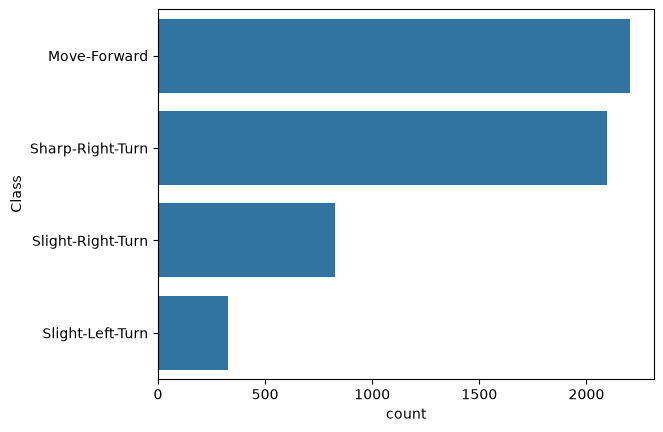

In [2]:
cols = ["SD_front", "SD_left", "SD_right", "SD_back", "Class"]
df = pd.read_csv("wall+following+robot+navigation+data/sensor_readings_4.data", header=None, names=cols)

contagem = df["Class"].value_counts()
print(f"Número de classes: {df['Class'].nunique()}")
print(f"Total de instâncias: {len(df)}\n")
print(pd.DataFrame({"Instâncias": contagem, "%": (contagem / len(df) * 100).round(2)}))

sns.countplot(data=df, y="Class", order=contagem.index);

## Valor médio, variância, assimetria e curtose dos atributos por classe.

In [3]:
stats = df.groupby("Class").agg(["mean", "var", "skew", "kurt"])

nomes = {"mean": "Valor médio", "var": "Variância", "skew": "Assimetria", "kurt": "Curtose (excesso)"}
for stat, nome in nomes.items():
    print(f"\n{nome}")
    display(stats.xs(stat, axis=1, level=1).round(4))


Valor médio


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,1.5849,0.6523,1.8633,1.0806
Sharp-Right-Turn,0.7996,0.6635,1.9121,1.4343
Slight-Left-Turn,1.4563,1.5631,1.6324,2.1536
Slight-Right-Turn,1.6836,0.4537,1.9535,1.0320



Variância


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,0.4679,0.0090,0.2831,0.3415
Sharp-Right-Turn,0.0054,0.1091,0.4487,1.1213
Slight-Left-Turn,0.1052,0.2756,0.0983,0.2068
Slight-Right-Turn,0.2816,0.0016,0.1239,0.0906



Assimetria


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,1.4676,0.1689,1.1636,3.3182
Sharp-Right-Turn,-1.8275,7.7705,0.6696,1.9332
Slight-Left-Turn,0.0562,1.5785,0.5138,1.8763
Slight-Right-Turn,2.1729,-1.4847,1.9960,-0.2994



Curtose (excesso)


,SD_front,SD_left,SD_right,SD_back
Class,,,,
Move-Forward,1.9510,-0.9421,0.6979,17.1768
Sharp-Right-Turn,4.0927,79.1589,-0.5184,3.2583
Slight-Left-Turn,-1.2854,5.0184,0.3170,10.4767
Slight-Right-Turn,8.1598,1.2486,7.8079,-0.1694


## Histogramas dos atributos (aproximação da densidade marginal de cada atributo)

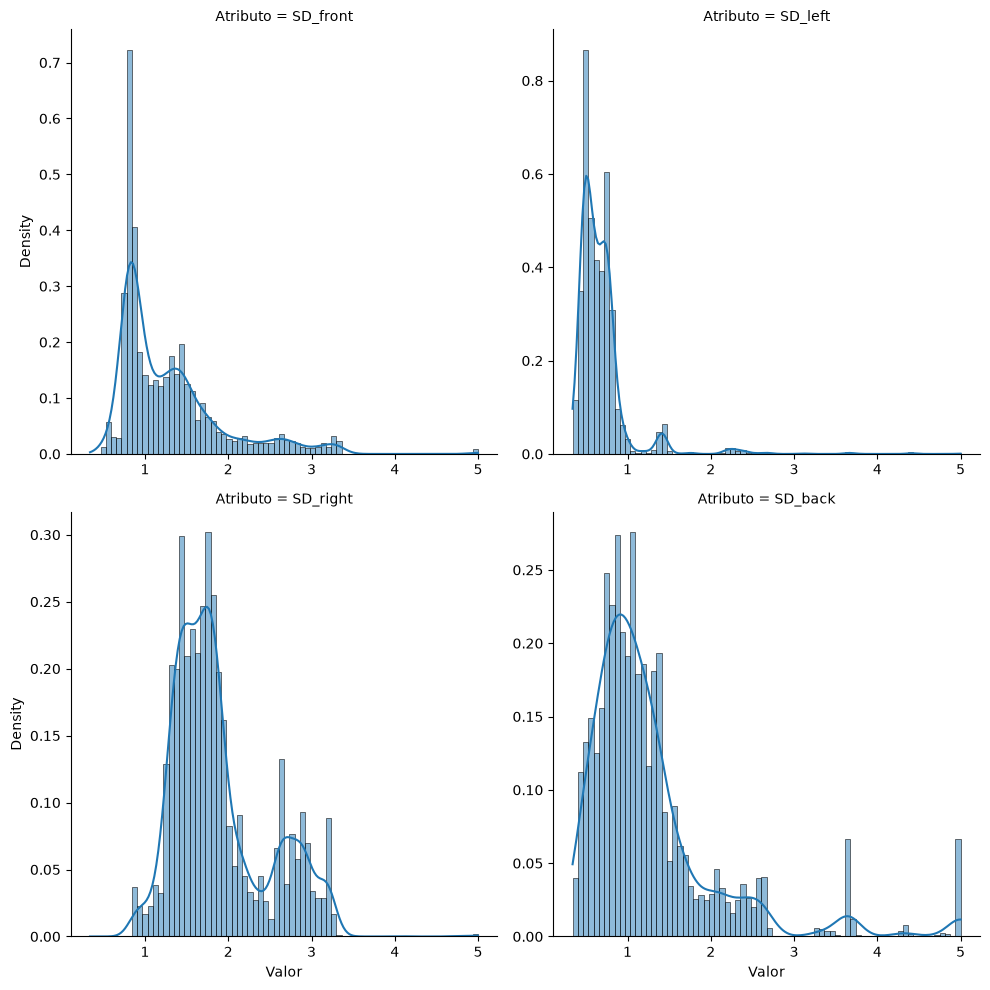

In [4]:
longo = df.melt(id_vars="Class", var_name="Atributo", value_name="Valor")

sns.displot(
    longo, x="Valor", col="Atributo", col_wrap=2,
    stat="density", kde=True,
    facet_kws={"sharex": False, "sharey": False},
);

## Scatterplot map com todas as combinações de pares de variáveis de entrada

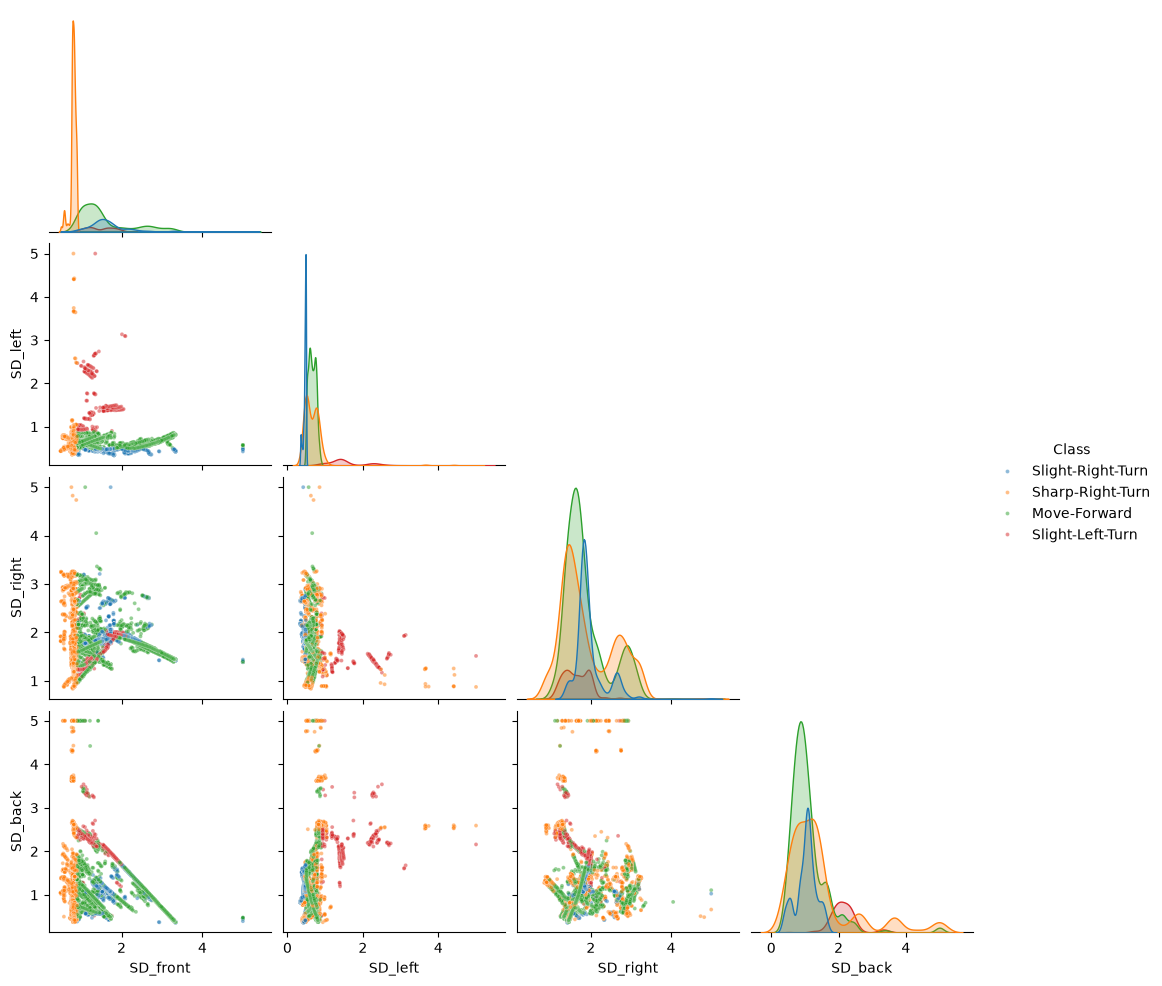

In [5]:
sns.pairplot(df, hue="Class", corner=True, plot_kws={"s": 8, "alpha": 0.5});

## Calcular a matriz de correlação dos atributos

,SD_front,SD_left,SD_right,SD_back
SD_front,1.0000,-0.0286,-0.1029,-0.2176
SD_left,-0.0286,1.0000,-0.2040,0.3317
SD_right,-0.1029,-0.2040,1.0000,-0.0393
SD_back,-0.2176,0.3317,-0.0393,1.0000


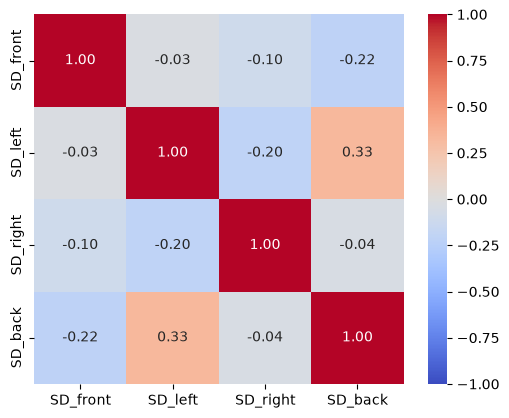

In [6]:
corr = df.drop(columns="Class").corr()
display(corr.round(4))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True);